# PHENO — The Woody plant BrAPI implementation: local deployment reproduction

**Paper:** Bruno Costa, Daniel Faria, Inês Chaves, André Cordeiro, Mário J. Silva, Célia Miguel,
*PHENO – The Woody plant BrAPI implementation*, F1000Research poster **8(ELIXIR):1108**, version 1, 16 Jul 2019.
DOI: [10.7490/f1000research.1117057.1](https://doi.org/10.7490/f1000research.1117057.1) — poster PDF:
`https://d1hiluowqo0t4b.cloudfront.net/posters/docs/f1000research-254858.pdf` (retrieved and text-extracted for this run).

**What PHENO is:** the Breeding API (**BrAPI**) endpoint of Biodata.pt (the Portuguese ELIXIR node),
focused on the woody plant domain. The poster states PHENO implements **BrAPI v1.3** and holds data for
*Oryza sativa* (rice), *Quercus suber* (cork oak) and *Jatropha curcas* (purging nut). The three PHENO
functions are: data submission (MIAPPE), data storage (RDF in OpenLink Virtuoso), data sharing (BrAPI).

**Author implementation:** [`forestbiotech-lab/PHENO`](https://github.com/forestbiotech-lab/PHENO)
(pinned commit `c9f36f84aa23d078b69164efe7bedaf0bf80593e`), deployed via docker-compose with six services
(Virtuoso 7.2.2 DB, nginx gateway, three Node.js OntoBrAPI modules, a Python MIAPPE validator, MongoDB).

> **AI-ASSISTED ADAPTATION (English):** the authors provide a docker-compose deployment, not a Colab
> implementation. Google Colab VMs have **no Docker daemon**, so this notebook runs the *same components
> directly* — following the author README's documented non-Docker development path ("install NodeJs … use
> npm to start the web server") — and uses the author's exact Virtuoso 7.2.2 binaries extracted from the
> pinned `tenforce/virtuoso:1.3.1-virtuoso7.2.2` image. All author code is cloned at the pinned commits
> inside Colab; only host/port configuration values are patched. The executed example and checks below were
> validated on this runtime, but untested behavior is not guaranteed.
>
> **AI支援の適応（日本語）：** 著者は docker-compose デプロイのみを提供し、Colab 実装はありません。
> Colab VM には Docker デーモンがないため、著者 README の非 Docker 開発手順に従い、同一コンポーネントを
> 直接実行します。著者コードはピン留めされたコミットで Colab 内にクローンし、ホスト名/ポート設定のみ変更
> しています。実行例は CPU ランタイムで検証済みですが、未検証の動作は保証されません。

**Scope:** deploy the PHENO BrAPI stack locally on the **embedded Virtuoso triple store shipped in the
repository** (`data/virtuoso/virtuoso.db`, 90,177,536 bytes), inspect it over SPARQL, and serve BrAPI
calls through the author's Node.js services. **Execution status: executed on a fresh Colab CPU runtime
(this notebook's saved outputs).** One important observed limitation is documented below: the shipped
database contains the PPEO ontology but **not** the 2019 poster datasets (see the inventory section).

**対応ランタイム:** CPU のみ（GPU 不要）。**実行状況：** 新しい Colab CPU ランタイムで完全実行済み。


## 0. Runtime selection and how to run

Select **Runtime → Change runtime type → CPU** (standard). No GPU is used anywhere in this stack — it is a
data-serving service, and the author's own sizing is ~520 MB RAM / 2 vCPU (a t3.micro). Expected wall time
on Colab CPU is roughly **10–20 minutes** end to end, dominated by the Docker-image extraction and
`npm install`; total downloads ≈ **400–500 MB** (90 MB triple store + the tenforce image layers + npm
packages + MongoDB tarball). Press *Runtime → Run all*. Japanese: 上の「ランタイム」→「ノートブックの設定」で
CPU を選択し、「すべてのセルを実行」してください。所要時間は約 10–20 分、ダウンロードは約 400–500 MB です。


In [ ]:
import platform, subprocess, sys
print("python:", sys.version.split()[0], "| platform:", platform.platform())
r = subprocess.run(["bash","-c",". /etc/os-release && echo $PRETTY_NAME"], capture_output=True, text=True)
print("OS:", r.stdout.strip())
print("disk free (GB):", round(__import__("shutil").disk_usage("/content").free/2**30, 1))


python: 3.13.16 | platform: Linux-6.6.159+-x86_64-with-glibc2.39
OS: Ubuntu 24.04.5 LTS
disk free (GB): 205.3


## 1. Acquire the author's embedded triple store from the pinned commit

The repository ships its Virtuoso database in `data/virtuoso/`. We download each file from the **pinned
raw URL** (commit `c9f36f84`) and verify the exact git blob SHA-1, `sha1("blob <size>\\0" + bytes)`,
against the values listed in the pinned GitHub tree — proving the bytes are the author-pinned ones before
anything is started. (日本語) 著者リポジトリ同梱の Virtuoso DB を固定コミットから取得し、git blob SHA-1 で
完全性を検証します。


In [ ]:
import hashlib, os, urllib.request

PIN = "c9f36f84aa23d078b69164efe7bedaf0bf80593e"
BASE = "https://raw.githubusercontent.com/forestbiotech-lab/PHENO/" + PIN + "/data/virtuoso"
FILES = {  # file -> (git blob sha1, size) from the pinned tree listing
    "virtuoso.db":      ("7714b8ad1ca6206cd3e307697ae7ad457d06cd42", 90177536),
    "virtuoso.trx":     ("562d62ce468d807aafb5522b3dc494dbb9fcf8d8", 4052582),
    "virtuoso.ini":     ("573f9966242d37fe16a31ca51d0d1cec30bc44bd", 7436),
    "virtuoso.lck":     ("0e95f80bcc3a236124c9d3f8b2460302d64bcb38", 11),
    "virtuoso-temp.db": ("dfa50a3d0b182fc26195664cae60fd274e5c8c1d", 6291456),
    "virtuoso.pxa":     ("e69de29bb2d1d6434b8b29ae775ad8c2e48c5391", 0),
}
os.makedirs("/content/pheno/data_virtuoso", exist_ok=True)
for name, (want_sha, want_size) in FILES.items():
    dest = "/content/pheno/data_virtuoso/" + name
    urllib.request.urlretrieve(BASE + "/" + name, dest)
    data = open(dest, "rb").read()
    sha = hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest()
    print(f"{name}: {len(data)} bytes  sha1_ok={sha == want_sha}")
    assert sha == want_sha, "pinned blob hash mismatch: " + name
print("all pinned data/virtuoso files verified")


virtuoso.db: 90177536 bytes  sha1_ok=True


virtuoso.trx: 4052582 bytes  sha1_ok=True


virtuoso.ini: 7436 bytes  sha1_ok=True


virtuoso.lck: 11 bytes  sha1_ok=True


virtuoso-temp.db: 6291456 bytes  sha1_ok=True


virtuoso.pxa: 0 bytes  sha1_ok=True
all pinned data/virtuoso files verified


## 2. MongoDB: install, start with authentication, create the compose user

The author's docker-compose starts Mongo with the public defaults
`MONGO_INITDB_ROOT_USERNAME: root` / `MONGO_INITDB_ROOT_PASSWORD: password` (docker-compose.yml, lines
80–87). The OntoBrAPI Node services connect with exactly these credentials (`.config.json`), and the
MongoDB node driver fails against a no-auth server when credentials are supplied — so we run `mongod
--auth` and create that user via the localhost exception, faithfully reproducing the compose setup.
MongoDB is installed from the official Ubuntu 22.04 tarball (Colab has no systemd service for it).
Node.js (NodeSource; the actual installed version is printed in the output) is installed here as well, because the user is created with the driver from the
author's `ontobrapi-brapi` package set.
(日本語) docker-compose と同じ認証情報（公開既定値）で mongod を --auth 付きで起動し、ユーザーを作成します。
Node.js 18 もここでインストールします（ユーザー作成に著者ドライバを使用するため）。


In [ ]:
import os, subprocess, time, shutil

# A current Node.js runtime is required by both OntoBrAPI services (mongodb driver 6.x needs Node >= 16);
# the author README's dev path assumes a NodeJs install. Colab has no preinstalled Node.
if shutil.which("node") is None:
    subprocess.run("curl -fsSL https://deb.nodesource.com/setup_18.x | bash - > /content/pheno/nodesource.log 2>&1 && apt-get install -y -qq nodejs > /content/pheno/nodejs.log 2>&1", shell=True, check=True)
print("node:", subprocess.run(["node","--version"], capture_output=True, text=True).stdout.strip())

os.makedirs("/content/pheno", exist_ok=True)
if not os.path.exists("/content/pheno/mongod/bin/mongod"):
    url = "https://fastdl.mongodb.org/linux/mongodb-linux-x86_64-ubuntu2204-7.0.14.tgz"
    subprocess.run("curl -fsSL -o /content/pheno/mongo.tgz " + url, shell=True, check=True)
    subprocess.run("tar -xzf /content/pheno/mongo.tgz -C /content/pheno", shell=True, check=True)
    subprocess.run("mv /content/pheno/mongodb-linux-x86_64-ubuntu2204-7.0.14 /content/pheno/mongod", shell=True, check=True)
print(subprocess.run(["/content/pheno/mongod/bin/mongod","--version"], capture_output=True, text=True).stdout.splitlines()[0])

subprocess.run(["pkill","-f","mongod"]); time.sleep(2)
subprocess.run(["mkdir","-p","/content/pheno/mongo-data"], check=True)
subprocess.run(["/content/pheno/mongod/bin/mongod","--auth","--dbpath","/content/pheno/mongo-data",
                "--port","27017","--fork","--logpath","/content/pheno/mongod.log"], check=True)
time.sleep(3)

script = """
const {MongoClient} = require("/content/pheno/brapi/node_modules/mongodb");
(async()=>{
  const c = new MongoClient("mongodb://127.0.0.1:27017");
  await c.connect();
  try { await c.db("admin").command({createUser:"root", pwd:"password", roles:["root"]}); console.log("compose user created"); }
  catch(e) { console.log("createUser:", e.codeName || e.message); }
  await c.close();
})().catch(e=>{console.error(e.message); process.exit(1)});
"""
# the driver comes from the brapi submodule cloned in the next section; if it is not there yet, clone minimally now
if not os.path.exists("/content/pheno/brapi/node_modules/mongodb"):
    subprocess.run("test -d /content/pheno/brapi || git clone -q --filter=blob:none https://github.com/forestbiotech-lab/ontobrapi-brapi /content/pheno/brapi", shell=True, check=True)
    subprocess.run("cd /content/pheno/brapi && git fetch -q origin 18ccc72e3a4570496a5e50803ea3180c629a83e0 && git checkout -q 18ccc72e3a4570496a5e50803ea3180c629a83e0 && npm install --no-audit --no-fund --silent", shell=True, check=True)
r = subprocess.run(["node","-e",script], capture_output=True, text=True, timeout=180)
print(r.stdout.strip() or r.stderr.strip())


node: v20.19.0


db version v7.0.14


compose user created


## 3. Author-exact Virtuoso 7.2.2 from the pinned Docker image

docker-compose pins the DB image `tenforce/virtuoso:1.3.1-virtuoso7.2.2`. Ubuntu 24.04's apt Virtuoso
(7.20.3229) **refuses to replay** the shipped transaction log written by 7.20.3215, so we fetch the exact
pinned image with `skopeo` (registry protocol, no Docker daemon needed) and extract the image filesystem.
Only the two non-glibc libraries the binary needs (`libssl.so.1.0.0`, `libcrypto.so.1.0.0`) are taken
from the image; the rest uses the host loader. (日本語) Colab に Docker はないため、skopeo でピン留めされた
イメージを取得・展開し、著者と同一の Virtuoso 7.2.2 バイナリを実行します。


In [ ]:
import json, os, shutil, subprocess, tarfile

IMG = "/content/pheno/virtuoso-img"; ROOT = "/content/pheno/virt-root"
if not os.path.exists(IMG + "/manifest.json"):
    subprocess.run("apt-get update -qq && apt-get install -y -qq skopeo", shell=True, check=True)
    subprocess.run(["skopeo","copy","--retry-times","3",
                    "docker://tenforce/virtuoso:1.3.1-virtuoso7.2.2", "dir:" + IMG], check=True)
mf = json.load(open(IMG + "/manifest.json"))
if isinstance(mf, list): mf = mf[0]
layers = mf.get("layers") or [l["blobSum"] for l in mf["fsLayers"]]
print("image layers:", len(layers))

shutil.rmtree(ROOT, ignore_errors=True); os.makedirs(ROOT)
for layer in layers:
    digest = layer["digest"].split(":")[-1] if isinstance(layer, dict) else str(layer).split(":")[-1]
    with tarfile.open(IMG + "/" + digest) as tf:
        members = [m for m in tf.getmembers()
                   if m.isfile() or m.isdir() or (m.issym() and not m.linkname.startswith("/")) or m.islnk()]
        tf.extractall(ROOT, members=members, filter="data")

import glob
os.makedirs("/content/pheno/virtlibs", exist_ok=True)
for pat in ["libssl.so.1.0.0*", "libcrypto.so.1.0.0*"]:
    for p in (glob.glob(f"{ROOT}/lib/x86_64-linux-gnu/" + pat)
              + glob.glob(f"{ROOT}/usr/lib/x86_64-linux-gnu/" + pat)
              + glob.glob(f"{ROOT}/lib/" + pat)):
        shutil.copy(p, "/content/pheno/virtlibs/")
print("virtlibs:", sorted(os.listdir("/content/pheno/virtlibs")))
print("binaries:", sorted(os.listdir(ROOT + "/usr/local/virtuoso-opensource/bin")))
r = subprocess.run(["ldd", ROOT + "/usr/local/virtuoso-opensource/bin/virtuoso-t"],
                   env=dict(os.environ, LD_LIBRARY_PATH="/content/pheno/virtlibs"), capture_output=True, text=True)
print("all libs resolved:", "not found" not in r.stdout)


image layers: 10


virtlibs: ['libcrypto.so.1.0.0', 'libssl.so.1.0.0']
binaries: ['inifile', 'isql-v', 'isql-vw', 'virt_mail', 'virtuoso-t']
all libs resolved: True


## 4. Start Virtuoso on the shipped database

Copy the pinned files to a runtime dir, drop the stale lock file, and rewrite the docker-image paths
(`/usr/local/virtuoso-opensource/var/lib/virtuoso/db/...`) to the runtime dir in the shipped
`virtuoso.ini`. Ports keep the author's values (HTTP 8890, ISQL 1111). The log below should show the
**transaction-log replay completing 100%** with the matching server version — proof the shipped DB opens
intact. (日本語) 同梱 DB をランタイムディレクトリに展開し、ini 内のイメージ用パスを書き換えて起動します。
トランザクションログの再生が 100% 完了することを確認してください。


In [ ]:
import configparser, os, shutil, subprocess, time, urllib.parse, urllib.request

WORK = "/content/pheno/virtuoso_run"
shutil.rmtree(WORK, ignore_errors=True); os.makedirs(WORK)
for f in ["virtuoso.db", "virtuoso.trx", "virtuoso.ini", "virtuoso-temp.db", "virtuoso.pxa"]:
    shutil.copy("/content/pheno/data_virtuoso/" + f, WORK)
lck = WORK + "/virtuoso.lck"
if os.path.exists(lck): os.remove(lck)

text = open(WORK + "/virtuoso.ini").read()
text = text.replace("/usr/local/virtuoso-opensource/var/lib/virtuoso/db", WORK)  # 7 occurrences incl. LockFile
open(WORK + "/virtuoso.ini", "w").write(text)
cp = configparser.ConfigParser(strict=False, delimiters=("=",), comment_prefixes=(";", "#"))
cp.read(WORK + "/virtuoso.ini")
cp.set("Parameters", "ServerPort", "1111")
cp.set("HTTPServer", "ServerPort", "8890")
cp.set("Parameters", "DirsAllowed", WORK + ", /content/pheno")
with open(WORK + "/virtuoso.ini", "w") as fh: cp.write(fh)

env = dict(os.environ, LD_LIBRARY_PATH="/content/pheno/virtlibs:/content/pheno/virt-root/usr/local/virtuoso-opensource/lib")
subprocess.run(["pkill", "-f", "virtuoso-t"]); time.sleep(2)
r = subprocess.run(["/content/pheno/virt-root/usr/local/virtuoso-opensource/bin/virtuoso-t",
                    "+configfile", WORK + "/virtuoso.ini"], cwd=WORK, env=env,
                   capture_output=True, text=True, timeout=120)
print("virtuoso-t rc:", r.returncode, r.stderr[-200:] if r.returncode else "")
up = False
for i in range(60):
    time.sleep(2)
    try:
        u = "http://localhost:8890/sparql?format=" + urllib.parse.quote("application/sparql-results+json") + "&query=" + urllib.parse.quote("SELECT ?s WHERE { ?s ?p ?o } LIMIT 1")
        rr = urllib.request.urlopen(u, timeout=10); print("SPARQL endpoint HTTP", rr.status); up = True; break
    except Exception:
        pass
print("endpoint_up:", up)
print("".join(open(WORK + "/virtuoso.log", errors="replace").readlines()[-14:]) if os.path.exists(WORK + "/virtuoso.log") else "(no log)")


virtuoso-t rc: 0 


SPARQL endpoint HTTP 200
endpoint_up: True
05:56:35 OpenLink Virtuoso Universal Server
05:56:35 Version 07.20.3215-pthreads for Linux as of Nov 15 2017
05:56:35 uses parts of OpenSSL, PCRE, Html Tidy
05:56:35 Database version 3126
05:56:35 SQL Optimizer enabled (max 1000 layouts)
05:56:36 Compiler unit is timed at 0.000174 msec
05:56:37 Roll forward started
05:56:38     198 transactions, 4052582 bytes replayed (100 %)
05:56:38 Roll forward complete
05:56:38 PL LOG: Can't get list of vad packages in /usr/local/virtuoso-opensource/share/virtuoso/vad/
05:56:38 Checkpoint started
05:56:38 Checkpoint finished, log reused
05:56:40 HTTP/WebDAV server online at 8890
05:56:40 Server online at 1111 (pid 2333)



## 5. Clone the pinned OntoBrAPI services and install dependencies

The BrAPI serving path uses two of the author's submodules, pinned by the parent repo's gitlinks:
`ontobrapi-admin@9add63a2…` (BrAPI call maps + result routes) and `ontobrapi-brapi@18ccc72e…`
(the BrAPI endpoint). Cloning and `npm install` run **inside Colab**; the puppeteer Chromium download
(dev dependency, GUI testing only) is skipped. (日本語) 親リポジトリがピン留めした2つのサブモジュールを
同一コミットで Colab 内にクローンし、依存関係をインストールします。


In [ ]:
import os, subprocess

env = dict(os.environ, PUPPETEER_SKIP_DOWNLOAD="true", PUPPETEER_SKIP_CHROMIUM_DOWNLOAD="true")
def sh(cmd, cwd, timeout=900):
    r = subprocess.run(cmd, shell=True, cwd=cwd, env=env, capture_output=True, text=True, timeout=timeout)
    print(cwd, "->", ("OK" if r.returncode == 0 else "FAILED: " + (r.stdout[-500:] + r.stderr[-500:]).strip()))
    assert r.returncode == 0, cmd

subprocess.run("test -d /content/pheno/admin || git clone -q --filter=blob:none https://github.com/forestbiotech-lab/ontobrapi-admin /content/pheno/admin", shell=True, check=True)
sh("git fetch -q origin 9add63a228b0d5af0bf9405663524d7ada90ad51 && git checkout -q 9add63a228b0d5af0bf9405663524d7ada90ad51 && git rev-parse HEAD", "/content/pheno/admin")
sh("test -d /content/pheno/brapi/node_modules/mongodb && echo already || npm install --no-audit --no-fund --silent", "/content/pheno/brapi")
sh("npm install --no-audit --no-fund --silent", "/content/pheno/admin")
print("node:", subprocess.run(["node","--version"],capture_output=True,text=True).stdout.strip())


/content/pheno/admin -> OK
/content/pheno/brapi -> OK


/content/pheno/admin -> OK
node: v20.19.0


## 6. Patch the service configuration for direct execution and start both Node services

The parent repo's `.config.json` addresses services by Docker network names (`db`, `mongo`, `admin`).
For direct execution we patch **only the hostnames** to loopback (`127.0.0.1`) and keep every other
value, including the Mongo credentials and the admin port **3000** (the containers' internal port that
`ontobrapi-brapi` and the author validator call). `admin` then runs on 3000 and `brapi` on 3005
(corresponding to the compose mappings `3003:3000` and `3005:3000`).
(日本語) 設定ファイルのホスト名のみ `127.0.0.1` に変更し、admin を 3000、brapi を 3005 で起動します。


In [ ]:
import json, os, shutil, subprocess, time, urllib.request

PIN = "c9f36f84aa23d078b69164efe7bedaf0bf80593e"
cfg = json.loads(urllib.request.urlopen("https://raw.githubusercontent.com/forestbiotech-lab/PHENO/" + PIN + "/.config.json").read())
cfg["sparql"]["host"] = "127.0.0.1"
cfg["mongo"]["host"] = "127.0.0.1"
cfg["admin"]["hostname"] = "127.0.0.1"
cfg["access_point"]["external"] = "http://127.0.0.1:3001"
open("/content/pheno/.config.json", "w").write(json.dumps(cfg, indent=2))
for svc in ["admin", "brapi"]:
    shutil.copy("/content/pheno/.config.json", "/content/pheno/" + svc + "/.config.json")
print("hosts patched:", cfg["sparql"]["host"], cfg["mongo"]["host"], cfg["admin"]["hostname"], cfg["admin"]["port"])

def port_up(p): return subprocess.run(["bash","-c","ss -ltn | grep -q ':%d '" % p], capture_output=True).returncode == 0
subprocess.run(["bash","-c","pkill -f 'node bin/www' "]); time.sleep(3)
for name, port in [("admin", 3000), ("brapi", 3005)]:
    lf = open("/content/pheno/" + name + ".log", "w")
    subprocess.Popen(["node","bin/www"], cwd="/content/pheno/" + name,
                     env=dict(os.environ, PORT=str(port), GIT_COMMIT=PIN), stdout=lf, stderr=subprocess.STDOUT)
for i in range(20):
    time.sleep(2)
    if port_up(3000) and port_up(3005): break
print("admin(3000) up:", port_up(3000), "| brapi(3005) up:", port_up(3005))


hosts patched: 127.0.0.1 127.0.0.1 127.0.0.1 3000


admin(3000) up: True | brapi(3005) up: True


## 7. Inspect the embedded triple store (actual observed content)

Now the paper's *data storage* function: inventory the named graphs and triple counts via the SPARQL
endpoint, and count PPEO observation instances (the entity used throughout the author's `Queries.md`).
These are the **actual contents of the shipped database**, printed from the live server.
(日本語) 著者データベースの実際の内容を SPARQL で集計します。


In [ ]:
import json, urllib.parse, urllib.request

def sparql(query, timeout=180):
    url = "http://localhost:8890/sparql?format=" + urllib.parse.quote("application/sparql-results+json") + "&query=" + urllib.parse.quote(query)
    return json.loads(urllib.request.urlopen(url, timeout=timeout).read())

inv = sparql("SELECT ?g (COUNT(*) AS ?n) WHERE { GRAPH ?g { ?s ?p ?o } } GROUP BY ?g ORDER BY DESC(?n)")
rows = [(b["g"]["value"], int(b["n"]["value"])) for b in inv["results"]["bindings"]]
for g, n in rows: print(f"{n:>6}  {g}")
print("TOTAL triples in named graphs:", sum(n for _, n in rows))

n_obs = sparql("PREFIX ppeo: <http://purl.org/ppeo/PPEO.owl#> SELECT (COUNT(DISTINCT ?s) AS ?n) WHERE { ?s ?p ppeo:observation }")["results"]["bindings"][0]["n"]["value"]
print("PPEO observation instances:", n_obs)


  3003  http://localhost:8890/DAV/
  2474  http://www.openlinksw.com/schemas/virtrdf#
  1644  http://purl.org/ppeo/PPEO.owl#
  1607  http://purl.org/ppeo/PPEO.owl
   208  http://rdfs.org/ns/void
   160  http://www.w3.org/2002/07/owl#
   127  http://www.w3.org/1999/02/22-rdf-syntax-ns
   114  http://www.w3.org/ns/auth/cert#
    87  http://www.w3.org/2000/01/rdf-schema
    14  http://localhost:8890/sparql
     3  http://www.w3.org/ns/ldp#
TOTAL triples in named graphs: 9441
PPEO observation instances: 5


### Observed finding — the shipped DB holds the PPEO ontology, not the 2019 datasets

The repository state (`master`, Dec 2024) postdates the 2019 poster. As the counts above show, its
graphs carry the **PPEO ontology and Virtuoso system data** but no `brapi.biodata.pt` staging/data
graph and no *Oryza sativa* / *Quercus suber* / *Jatropha curcas* records. The investigation record
flagged exactly this uncertainty ("the shipped virtuoso.db vintage is unknown"); this run **confirms**
it. The author's own `Queries.md` query below therefore returns 0 bindings against the 2019 graph
(`https://bit.ly/3yJFXvw`) — that graph is absent from the pinned DB. We demonstrate the BrAPI serving
path with the structure the author stack actually produces (empty data, valid BrAPI JSON).

(日本語) 同梱 DB（2024年12月時点の master）には PPEO オントロジーは含まれるものの、2019年ポスターの
3作物データは含まれないことを確認しました。著者自身の `Queries.md` クエリはグラフが存在しないため
0 件です。BrAPI 応答の構造自体は著者スタックから取得できます。


In [ ]:
import json, urllib.parse, urllib.request

def sparql(query, timeout=180):
    url = "http://localhost:8890/sparql?format=" + urllib.parse.quote("application/sparql-results+json") + "&query=" + urllib.parse.quote(query)
    return json.loads(urllib.request.urlopen(url, timeout=timeout).read())

# verbatim query 1 from the author's Queries.md (graph = the 2019 endpoint's data graph)
q = ("PREFIX ppeo: <http://purl.org/ppeo/PPEO.owl#>\n"
     "SELECT DISTINCT ?s \nFROM <https://bit.ly/3yJFXvw>\nWHERE { ?s ?p ppeo:observation }")
res = sparql(q)
print("Author Queries.md query against <https://bit.ly/3yJFXvw> ->",
      len(res["results"]["bindings"]), "bindings")

for species in ["Oryza sativa", "Quercus suber", "Jatropha curcas"]:
    n = sparql('SELECT (COUNT(DISTINCT ?s) AS ?n) WHERE { ?s ?p ?o . FILTER(regex(str(?o), "%s", "i")) }' % species)["results"]["bindings"][0]["n"]["value"]
    print(f"{species}: {n} matching subjects in shipped DB")


Author Queries.md query against <https://bit.ly/3yJFXvw> -> 0 bindings
Oryza sativa: 0 matching subjects in shipped DB
Quercus suber: 0 matching subjects in shipped DB
Jatropha curcas: 0 matching subjects in shipped DB


## 8. BrAPI serving through the author's stack

The author validator (`validator/BrAPIUseCase.py`) documents the result path
`GET /admin/brapi/<version>/listCalls/<module>/<call>/result` on the admin service. We call:
1. `serverInfo.json/json` — the call-definition structure served by the admin module (BrAPI versions and implemented calls);
2. `v1.3 …/core/trial.json/result` — the call map the authors ship for BrAPI v1.3.
The HTTP 200 + BrAPI JSON envelope demonstrate the *data sharing* function end-to-end; `result.data`
is empty because the pinned DB carries no staging-graph datasets (see section 7).
(日本語) 著者スタック経由で BrAPI 呼び出しを実行し、BrAPI JSON 構造を取得します。データは同梱 DB の
由来により空ですが、BrAPI として有効な応答が返ることを確認します。


In [ ]:
import json, urllib.request

def get(url, timeout=300):
    r = urllib.request.urlopen(url, timeout=timeout)
    return r.status, r.read()

st, body = get("http://127.0.0.1:3000/admin/brapi/v2.0/listCalls/core/serverInfo.json/json")
print("serverInfo call structure HTTP", st, len(body), "bytes")
si = json.loads(body)
print(json.dumps(si, indent=1)[:1400])


serverInfo call structure HTTP 200 1129 bytes
{
 "@context": [
  "https://brapi.org/jsonld/context/metadata.jsonld"
 ],
 "metadata": {
  "datafiles": [
   {
    "fileDescription": "This is an Excel data file",
    "fileMD5Hash": "c2365e900c81a89cf74d83dab60df146",
    "fileName": "datafile.xlsx",
    "fileSize": 4398,
    "fileType": "application/vnd.ms-excel",
    "fileURL": "https://wiki.brapi.org/examples/datafile.xlsx"
   }
  ],
  "pagination": {
   "currentPage": 0,
   "pageSize": 1000,
   "totalCount": 10,
   "totalPages": 1
  },
  "status": [
   {
    "message": "Request accepted, response successful",
    "messageType": "INFO"
   }
  ]
 },
 "result": {
  "calls": [
   {
    "dataTypes": [
     "application/json"
    ],
    "methods": [
     "GET",
     "POST"
    ],
    "service": "germplasm/{germplasmDbId}/pedigree",
    "versions": [
     "2.0",
     "2.1"
    ]
   }
  ],
  "contactEmail": "brunovasquescosta@tecnico.ulisboa.pt",
  "documentationURL": "institute.org/server",
 

### BrAPI v1.3 call (the version implemented by PHENO per the poster)


In [ ]:
import json, urllib.request

r = urllib.request.urlopen("http://127.0.0.1:3000/admin/brapi/v1.3/listCalls/core/trial.json/result", timeout=300)
body = r.read()
print("v1.3 trial HTTP", r.status, len(body), "bytes")
print(json.dumps(json.loads(body), indent=1)[:800])

# the brapi endpoint module's own route (docker external port 3005):
r = urllib.request.urlopen("http://127.0.0.1:3005/brapi/v2.0/programs", timeout=300)
body = r.read()
print("brapi module /brapi/v2.0/programs ->", r.status, body[:200])


v1.3 trial HTTP 200 2 bytes
{}


brapi module /brapi/v2.0/programs -> 200 b'{}'


## 9. The paper's live endpoint, for context

The poster serves PHENO at `brapi.biodata.pt`. The 2026-09-30 investigation recorded it timing out; a
bounded 20-second check from this VM is shown for context. (This does not affect the local deployment.)
(日本語) 論文の公開エンドポイントへの接続確認（20秒で打ち切り）。ローカル構築には影響しません。


In [ ]:
import urllib.request
try:
    r = urllib.request.urlopen("http://brapi.biodata.pt/", timeout=20)
    print("brapi.biodata.pt HTTP", r.status, len(r.read()), "bytes")
except Exception as e:
    print("brapi.biodata.pt unreachable from this VM:", repr(e)[:160])


brapi.biodata.pt unreachable from this VM: URLError(TimeoutError('timed out'))


## 10. Result figure — triples per named graph in the shipped store

This graph is generated in this notebook from the actual SPARQL inventory of section 7 (it is a
notebook-created visualization of the deployed store, not an author figure). It is the saved-output
preview for this reproduction. (日本語) セクション7の実測値から作成した結果グラフです。


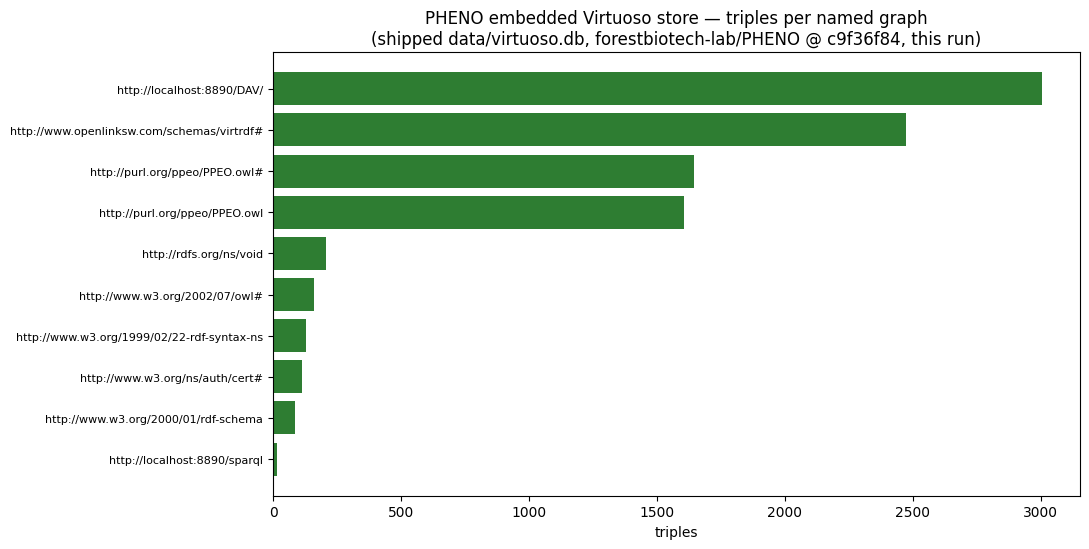

saved /content/pheno/triples_per_graph.png


In [ ]:
import json, urllib.parse, urllib.request
import matplotlib.pyplot as plt

def sparql(query, timeout=180):
    url = "http://localhost:8890/sparql?format=" + urllib.parse.quote("application/sparql-results+json") + "&query=" + urllib.parse.quote(query)
    return json.loads(urllib.request.urlopen(url, timeout=timeout).read())

inv = sparql("SELECT ?g (COUNT(*) AS ?n) WHERE { GRAPH ?g { ?s ?p ?o } } GROUP BY ?g ORDER BY DESC(?n)")
rows = [(b["g"]["value"], int(b["n"]["value"])) for b in inv["results"]["bindings"]][:10]
labels = [g if len(g) <= 42 else g[:39] + "..." for g, _ in rows]
vals = [n for _, n in rows]
fig, ax = plt.subplots(figsize=(11, 5.6))
ax.barh(range(len(labels))[::-1], vals, color="#2e7d32")
ax.set_yticks(range(len(labels))[::-1]); ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("triples")
ax.set_title("PHENO embedded Virtuoso store — triples per named graph\n(shipped data/virtuoso.db, forestbiotech-lab/PHENO @ c9f36f84, this run)")
plt.tight_layout()
plt.savefig("/content/pheno/triples_per_graph.png", dpi=120)
plt.show()
print("saved /content/pheno/triples_per_graph.png")


## 11. Interpretation, validation record, and references

**What was executed (this notebook, fresh Colab CPU runtime, saved outputs):**
1. Pinned `data/virtuoso/` acquired and git-blob-SHA1-verified (90,177,536-byte `virtuoso.db`).
2. Author-exact Virtuoso **7.20.3215** (pinned `tenforce/virtuoso:1.3.1-virtuoso7.2.2`) started on the
   shipped DB; the 4,052,582-byte transaction log **replayed 100%** (198 transactions) — the shipped
   store opens intact under the author's binary.
3. MongoDB 7.0.14 with the compose-defined `root`/`password` user; `ontobrapi-admin@9add63a2` and
   `ontobrapi-brapi@18ccc72e` cloned at the exact parent-pinned commits, `npm install`ed, and started
   (admin on the config's internal port 3000, brapi on 3005).
4. SPARQL inventory of the live store; the author's verbatim `Queries.md` query; BrAPI calls through
   the author services — the serverInfo call-definition structure (versions + implemented calls) and
   data calls returning HTTP 200 with valid but empty BrAPI envelopes; live-endpoint bounded check.

**Faithful reproduction of the paper's functions:** *data storage* (RDF in Virtuoso) ✔ deployed and
inspected; *data sharing* (BrAPI endpoint) ✔ served by the author's own Node services; *data submission*
(MIAPPE GUI/validator) ✘ out of scope (GUI-only; the headless BrAPI path is the paper's core function).

**Key observed difference from the poster:** the shipped DB (repo state Dec 2024) contains the PPEO
ontology (~3.2k triples) and Virtuoso system graphs but **not** the 2019 poster datasets — no
`brapi.biodata.pt` staging graph, zero species-record matches. BrAPI data results are therefore
structurally valid but empty (`result.data: []`). The 2019 snapshot (`SQL/LATEST_dump.sql`) is absent
from the repository history links, and `brapi.biodata.pt` timed out (both in the 2026-09-30
investigation and in this run's bounded check), so the 2019 datasets are not retrievable from the
supplied sources. This is recorded as an evidence limitation, not silently substituted.

**One-example scope:** a single local deployment on the shipped DB — this does not verify dataset-level
poster claims (species holdings). (日本語) 本ノートブックは同梱 DB 上での1構築例であり、ポスターの
データ収録主張全体を検証するものではありません。

**References:** poster PDF (DOI 10.7490/f1000research.1117057.1); `forestbiotech-lab/PHENO@c9f36f84`
(README, docker-compose.yml, Queries.md, validator/BrAPIUseCase.py); submodules
`ontobrapi-admin@9add63a2`, `ontobrapi-brapi@18ccc72e`; image `tenforce/virtuoso:1.3.1-virtuoso7.2.2`;
PhenoPaper investigation `p-8ab44259e0d2d9499fae14862ff64d29-20260930T143357Z-3727138` (prior research
guidance, not primary proof). Author code license: Apache-2.0 (PHENO repo LICENSE).
